# Training models to text on the kryptonite-n data sets & LoRA implementation on the KryptoNet model


In [1]:
import copy
import warnings
from math import comb
import numpy as np
import scipy.linalg as sla
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from kryptonet import load_kryptonet

# numpy 2.0 with Apple's Accelerate library raises spurious floating-point warnings in matrix products;
# the results are correct.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "no-latex"])
except ImportError:
    pass
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8})
COLORS = {20: "#4878d0", 30: "#ee854a", 40: "#6acc64"}
NS = (20, 30, 40)
TARGET = 0.90


def load(name):
    return np.load(f"Datasets/{name}-X.npy"), np.load(f"Datasets/{name}-y.npy")


def split(X, y):
    """60% train, 20% validation, 20% test."""
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)
    return X_train, y_train, X_test, y_test


def poly_logreg(X_train, y_train, X_test, y_test, degree):
    """Logistic regression on explicit polynomial features."""
    poly = PolynomialFeatures(degree)
    logreg = LogisticRegression(max_iter=100, solver="sag", C=0.85)
    logreg.fit(poly.fit_transform(X_train), y_train)
    return float(logreg.score(poly.transform(X_test), y_test))

# LoRA implementation


In [17]:
class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r: int, alpha: float):
        super().__init__()
        self.base = base
        self.scale = alpha / r #sets the scaling factor for the LoRA parameters based on the rank and learning rate value
        self.lora_A = nn.Parameter(torch.zeros((r, base.in_features)))  
        self.lora_B = nn.Parameter(torch.zeros((base.out_features, r)))   #initialize LoRA parameters
        for p in self.base.parameters(): #ensure that the base model's parameters are not updated during training
            p.requires_grad = False
        
        nn.init.kaiming_uniform_(self.lora_A, a=np.sqrt(5)) #randomly initialize A parameters using Kaiming uniform initialization
        
    def forward(self, x):
        return self.base(x) + self.scale * (self.lora_B @ (self.lora_A @ x.T)).T

    @torch.no_grad()
    def merge(self):
        """Merge LoRA parameters into the base model."""
        self.base.weight += self.scale * (self.lora_B @ self.lora_A)
        return self.base
        
def make_lora_model(r=8, alpha=16, n_adapt=4, train_head=True):
    """Convert a linear layer to a LoRA linear layer."""
    m = load_kryptonet("kryptonet40.pt")
    for p in m.parameters():
        p.requires_grad_(False)
        
    lin = [i for i, l in enumerate(m) if isinstance(l, nn.Linear)]
    for i in lin[:n_adapt]:
        m[i] = LoRALinear(m[i], r, alpha)
    if train_head: #trains the 5th layer of the model (the last linear layer) in addition to the LoRA layers
        for p in m[lin[-1]].parameters():
            p.requires_grad_(True)
    return m


               mean       std
r  lr                        
4  0.0005  0.911667  0.040104
   0.0010  0.946111  0.031813
   0.0020  0.920556  0.059216
8  0.0005  0.919444  0.038345
   0.0010  0.922222  0.045164
   0.0020  0.957778  0.008389
16 0.0005  0.904444  0.037503
   0.0010  0.948333  0.013017
   0.0020  0.935556  0.052502
LoRA r=8, lr=0.002: 0.9370
{'Zero-shot': 0.481, 'Linear probe': 0.463, 'LoRA': 0.937, 'MLP probe': 0.493}


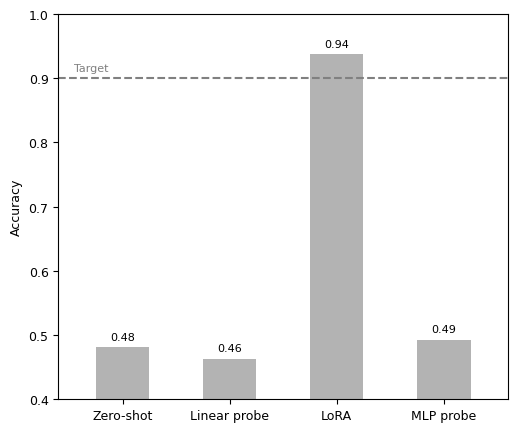

In [35]:
import itertools


def accuracy(net, X, y):
    net.eval()
    with torch.no_grad():
        return float(((net(torch.from_numpy(X)).squeeze(1) > 0).long().numpy() == y).mean())


def fit(net, X, y, params, lr, epochs=300, patience=40, bs=128):
    """Adam on `params` with early stopping on a 20% validation split; restores the best weights."""
    X, y = torch.from_numpy(X), torch.from_numpy(y).float()
    perm = torch.randperm(len(y)); nv = len(y) // 4
    Xv, yv, Xa, ya = X[perm[:nv]], y[perm[:nv]], X[perm[nv:]], y[perm[nv:]]
    opt = torch.optim.Adam(params, lr=lr)
    best, state, since = -1.0, None, 0
    for _ in range(epochs):
        net.train(); p = torch.randperm(len(ya))
        for i in range(0, len(ya), bs):
            bi = p[i:i + bs]
            loss = torch.nn.functional.binary_cross_entropy_with_logits(net(Xa[bi]).squeeze(1), ya[bi])
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            va = float(((net(Xv).squeeze(1) > 0).float() == yv).float().mean())
        if va > best:
            best, since, state = va, 0, copy.deepcopy(net.state_dict())
        else:
            since += 1
            if since >= patience:
                break
    net.load_state_dict(state)
    return net


X, y = load("kryptonite-40-adapt")
X_pool, X_test, y_pool, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_tr, X_sel, y_tr, y_sel = train_test_split(X_pool, y_pool, test_size=0.2, random_state=0)
base = load_kryptonet("kryptonet40.pt")
torch.manual_seed(0)
fig3 = {"Zero-shot": accuracy(base, X_test, y_test)}

probe = copy.deepcopy(base)
for p in probe.parameters():
    p.requires_grad_(False)
probe[-1] = torch.nn.Linear(probe[-1].in_features, 1)
fig3["Linear probe"] = accuracy(fit(probe, X_pool, y_pool, probe[-1].parameters(), lr=1e-2), X_test, y_test)

rows = []
for r, lr, seed in itertools.product((4, 8, 16), (5e-4, 1e-3, 2e-3), range(3)):
    torch.manual_seed(seed)
    net = make_lora_model(r=r, alpha=16, n_adapt=4, train_head=True)
    net = fit(net, X_tr, y_tr, [p for p in net.parameters() if p.requires_grad], lr)
    rows.append((r, lr, seed, accuracy(net, X_sel, y_sel)))

import pandas as pd
df = pd.DataFrame(rows, columns=["r", "lr", "seed", "acc"]).groupby(["r", "lr"]).acc.agg(["mean", "std"])
print(df)
r_best, lr_best = df["mean"].idxmax()

# final: retrain chosen config on the full pool, several seeds, touch test once

torch.manual_seed(4)
net = make_lora_model(r=r_best, alpha=16, n_adapt=4, train_head=True)
net = fit(net, X_pool, y_pool, [p for p in net.parameters() if p.requires_grad], lr_best)
best_acc = accuracy(net, X_test, y_test)
print(f"LoRA r={r_best}, lr={lr_best}: {best_acc:.4f}")
fig3["LoRA"] = best_acc


mlp_probe = copy.deepcopy(probe)
width = mlp_probe[-1].in_features
mlp_probe[-1] = torch.nn.Sequential(torch.nn.Linear(width, width), torch.nn.ReLU(), torch.nn.Linear(width, 1))
fig3["MLP probe"] = accuracy(fit(mlp_probe, X_pool, y_pool, mlp_probe[-1].parameters(), lr=1e-3), X_test, y_test)
print(fig3)



fig, ax = plt.subplots(figsize=(5.25, 4.4))
names, accs = list(fig3), list(fig3.values())
ax.bar(range(len(names)), accs, color="0.7", width=0.5)
for i, acc in enumerate(accs):
    ax.text(i, acc + 0.012, f"{acc:.2f}", ha="center", fontsize=8)
ax.axhline(TARGET, color="gray", ls="--", lw=1.5)
ax.text(-0.45, TARGET + 0.012, "Target", ha="left", fontsize=8, color="gray")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names); ax.set_xlim(-0.6, len(names) - 0.4)
ax.set_ylabel("Accuracy"); ax.set_ylim(0.4, 1.0)
fig.tight_layout(); plt.show()

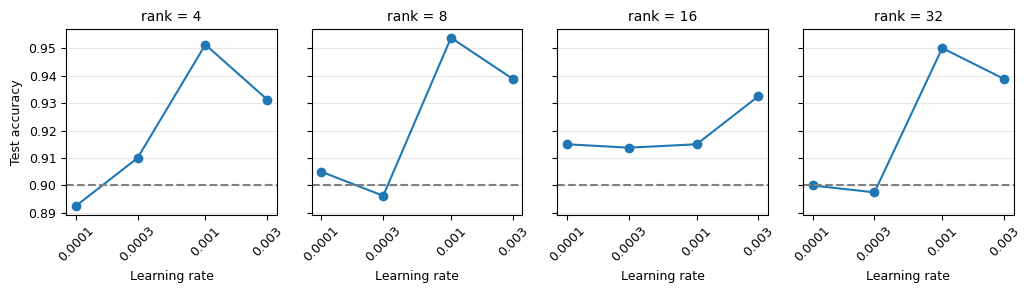

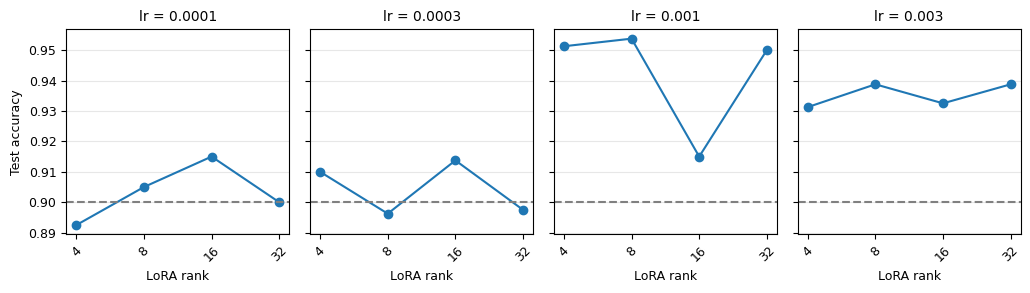

In [36]:
def plot_sweep(results, by="r"):
    kg, kx = (2, 3) if by == "r" else (3, 2)   # tuple index for panel grouping / x-axis
    xlabel = "Learning rate" if by == "r" else "LoRA rank"
    groups = sorted({t[kg] for t in results})
    xs = sorted({t[kx] for t in results})
    fig, axes = plt.subplots(1, len(groups), figsize=(2.6 * len(groups), 3), sharey=True)
    for ax, g in zip(axes, groups):
        pts = sorted((t[kx], t[1]) for t in results if t[kg] == g)
        ax.plot(*zip(*pts), marker="o")
        ax.axhline(TARGET, color="gray", ls="--", lw=1.5)
        ax.set_xscale("log", base=10 if by == "r" else 2)
        ax.set_xticks(xs); ax.set_xticklabels([f"{x:g}" for x in xs], rotation=45)
        ax.minorticks_off()
        ax.set_title(f"{'rank' if by == 'r' else 'lr'} = {g:g}")
        ax.set_xlabel(xlabel); ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("Test accuracy")
    fig.tight_layout(); plt.show()

plot_sweep(results, by="r")
plot_sweep(results, by="lr")